In [1]:
%pip install -q ldpc
import numpy as np
import matplotlib.pyplot as plt
import pickle
from ldpc import mod2, BpDecoder
import sys; sys.path.append("..")  # bb_code.py lives in the repo root
from bb_code import bb_code, is_failure

H_X, H_Z = bb_code()
n = H_Z.shape[1]
rank_HX = mod2.rank(H_X)

Note: you may need to restart the kernel to use updated packages.


In [6]:
p = 0.03      # error rate (we'll rerun at 0.04 afterwards)
N = 1000      # number of error shots
K = 30        # number of different update orders

rng = np.random.default_rng(7)
E = (rng.random((N, n)) < p).astype(np.uint8)    # all N errors at once: N × 72 table
S = ((E @ H_Z.T) % 2).astype(np.uint8)            # all N syndromes:      N × 36 table

perm_rng = np.random.default_rng(99)
orders = [perm_rng.permutation(n) for _ in range(K)]   # 30 random orderings of the 72 qubits

In [7]:
fails = np.zeros((K, N), dtype=bool)     # the ✅/❌ table: row = order, column = shot
conv  = np.zeros((K, N), dtype=bool) 

for k, order in enumerate(orders):
    dec = BpDecoder(H_Z, error_rate=p, max_iter=50, bp_method="minimum_sum",
                    schedule="serial", serial_schedule_order=order.tolist())
    for i in range(N):
        e_hat = dec.decode(S[i])
        conv[k, i]  = dec.converge
        fails[k, i] = is_failure(H_X, rank_HX, E[i], e_hat, dec.converge)
    print(f"order {k+1}/{K}: LER = {fails[k].mean():.4f}")

# baseline on the SAME shots: plain fixed serial (order 0, 1, 2, ..., 71)
dec = BpDecoder(H_Z, error_rate=p, max_iter=50, bp_method="minimum_sum", schedule="serial")
fails_fixed = np.array([is_failure(H_X, rank_HX, E[i], dec.decode(S[i]), dec.converge)
                        for i in range(N)])
print(f"fixed serial: LER = {fails_fixed.mean():.4f}")


order 1/30: LER = 0.0560
order 2/30: LER = 0.0580
order 3/30: LER = 0.0600
order 4/30: LER = 0.0560
order 5/30: LER = 0.0500
order 6/30: LER = 0.0570
order 7/30: LER = 0.0720
order 8/30: LER = 0.0610
order 9/30: LER = 0.0590
order 10/30: LER = 0.0570
order 11/30: LER = 0.0560
order 12/30: LER = 0.0600
order 13/30: LER = 0.0660
order 14/30: LER = 0.0490
order 15/30: LER = 0.0670
order 16/30: LER = 0.0710
order 17/30: LER = 0.0530
order 18/30: LER = 0.0670
order 19/30: LER = 0.0480
order 20/30: LER = 0.0640
order 21/30: LER = 0.0670
order 22/30: LER = 0.0600
order 23/30: LER = 0.0600
order 24/30: LER = 0.0600
order 25/30: LER = 0.0560
order 26/30: LER = 0.0530
order 27/30: LER = 0.0570
order 28/30: LER = 0.0660
order 29/30: LER = 0.0640
order 30/30: LER = 0.0560
fixed serial: LER = 0.0570


In [8]:
ler_per_order  = fails.mean(axis=1)    # one LER per order (average over shots)
fail_frac_shot = fails.mean(axis=0)    # per shot: fraction of orders that failed it

always_ok   = (fail_frac_shot == 0).mean()
always_fail = (fail_frac_shot == 1).mean()
sensitive   = 1 - always_ok - always_fail

print(f"fixed serial LER:          {fails_fixed.mean():.4f}")
print(f"LER across 30 orders:      mean {ler_per_order.mean():.4f}, "
      f"min {ler_per_order.min():.4f}, max {ler_per_order.max():.4f}")
print(f"shots always succeeding:   {always_ok:.1%}")
print(f"shots always failing:      {always_fail:.1%}")
print(f"order-sensitive shots:     {sensitive:.1%}")
print(f"oracle LER (best of 30):   {always_fail:.4f}")

any_conv = conv.any(axis=0)                     # did ANY order converge on this shot?
first    = conv.argmax(axis=0)                  # index of the first order that converged
restart_fail = np.where(any_conv, fails[first, np.arange(N)], True)

nonconv_share = (fails & ~conv).sum() / fails.sum()
print(f"restart LER (first converging of 30): {restart_fail.mean():.4f}")
print(f"failures due to non-convergence:      {nonconv_share:.1%}")

fixed serial LER:          0.0570
LER across 30 orders:      mean 0.0595, min 0.0480, max 0.0720
shots always succeeding:   78.1%
shots always failing:      0.2%
order-sensitive shots:     21.7%
oracle LER (best of 30):   0.0020
restart LER (first converging of 30): 0.0300
failures due to non-convergence:      53.8%


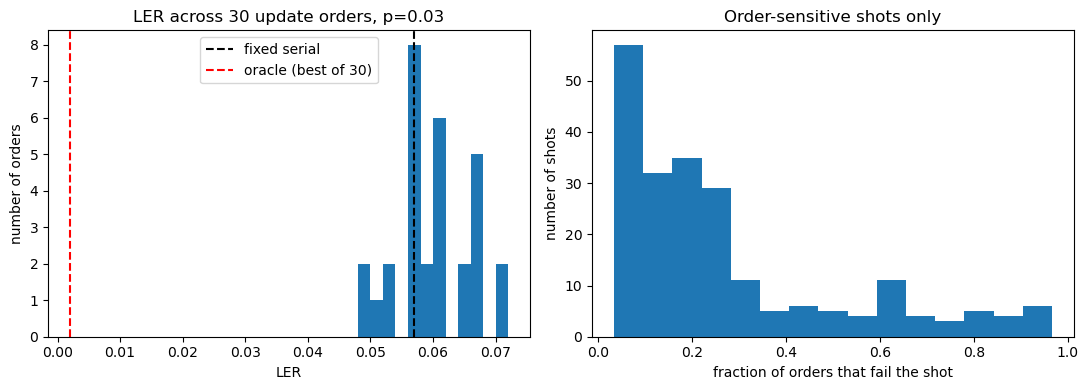

In [9]:
with open(f"taskB_p{p}.pkl", "wb") as f:
    pickle.dump({"fails": fails, "fails_fixed": fails_fixed, "orders": orders, "p": p, "conv": conv}, f)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(ler_per_order, bins=12)
ax1.axvline(fails_fixed.mean(), color="k", ls="--", label="fixed serial")
ax1.axvline(always_fail, color="r", ls="--", label="oracle (best of 30)")
ax1.set_xlabel("LER"); ax1.set_ylabel("number of orders")
ax1.set_title(f"LER across {K} update orders, p={p}")
ax1.legend()

sens = fail_frac_shot[(fail_frac_shot > 0) & (fail_frac_shot < 1)]
ax2.hist(sens, bins=15)
ax2.set_xlabel("fraction of orders that fail the shot")
ax2.set_ylabel("number of shots")
ax2.set_title("Order-sensitive shots only")

fig.tight_layout()
fig.savefig(f"taskB_p{p}.png", dpi=200, bbox_inches="tight")
plt.show()